# Experiment 2: Implementation of Multiple Linear Regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
data = {
    'Area': [1200, 1500, 1800, 2000, 2200, 2500, 1400, 1650, 1900, 2100, 2400, 2600, 1300, 1750, 2300, 2800, 1100, 1600, 1950, 2700],
    'Bedrooms': [2, 3, 3, 3, 4, 4, 2, 3, 3, 4, 4, 4, 2, 3, 4, 5, 2, 3, 3, 4],
    'Age': [10, 5, 8, 3, 4, 2, 12, 7, 6, 5, 3, 1, 15, 9, 4, 2, 14, 6, 5, 3],
    'Price': [240000, 315000, 360000, 410000, 455000, 520000, 275000, 335000, 385000, 430000, 495000, 550000, 250000, 350000, 470000, 590000, 215000, 325000, 400000, 560000]
}
df = pd.DataFrame(data)
print(df.head())

   Area  Bedrooms  Age   Price
0  1200         2   10  240000
1  1500         3    5  315000
2  1800         3    8  360000
3  2000         3    3  410000
4  2200         4    4  455000


In [3]:
X = df[['Area', 'Bedrooms', 'Age']]
y = df['Price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
print("Coefficients:", model.coef_)
print("Intercept:", round(model.intercept_, 2))

Coefficients: [  212.84813006 -1858.01829653 -1312.05498824]
Intercept: -2769.58


In [4]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("R2 Score:", round(r2, 4))
results = pd.DataFrame({'Actual': y_test.values, 'Predicted': np.round(y_pred, 2)})
print(results)

MAE: 5476.72
MSE: 43413718.01
R2 Score: 0.9969
   Actual  Predicted
0  240000  235811.59
1  325000  324341.04
2  590000  581290.98
3  315000  304368.28
4  385000  388195.48


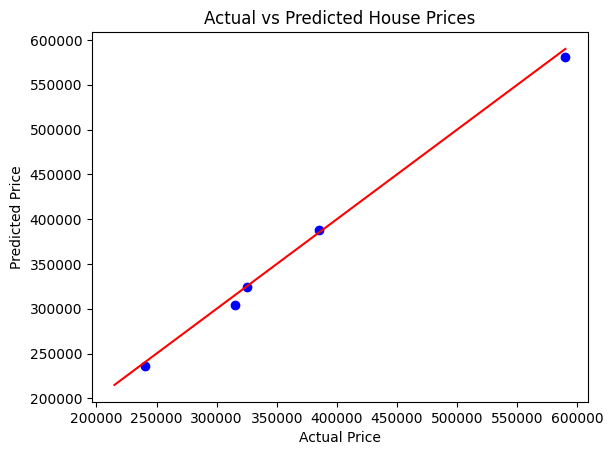

In [5]:
plt.scatter(y_test, y_pred, color='blue')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red')
plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.show()